# Machine Learning - Assignment 1
## Exercise B

In [2]:
# imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from matplotlib.colors import ListedColormap
from sklearn.base import clone
from sklearn.datasets import make_blobs
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.inspection import DecisionBoundaryDisplay

RANDOM_STATE = 269
CLASS_COLORS = ["#FF0000", "#0000FF"]  # class 0 = red, class 1 = blue

## B.I.1 Dataset 1

In [3]:
centers = np.array([[0.0, 0.0], [3.0, 3.0]])
X1, y1 = make_blobs(n_samples=[40, 40], centers=centers, cluster_std=1.2,
                    n_features=2, random_state=RANDOM_STATE)

df1 = pd.DataFrame(X1, columns=["x1", "x2"])
df1["class"] = y1
print(df1["class"].value_counts().sort_index())
df1.round(3)

class
0    40
1    40
Name: count, dtype: int64


,x1,x2,class
0,1.736,2.117,1
1,2.104,2.899,1
2,-0.722,-2.171,0
3,1.648,2.215,1
4,3.585,1.630,1
...,...,...,...
75,-0.104,0.302,0
76,4.240,2.179,1
77,-0.922,1.413,0
78,0.939,-2.034,0


## B.I.2 Dataset 2 (Dataset 1 + outliers)

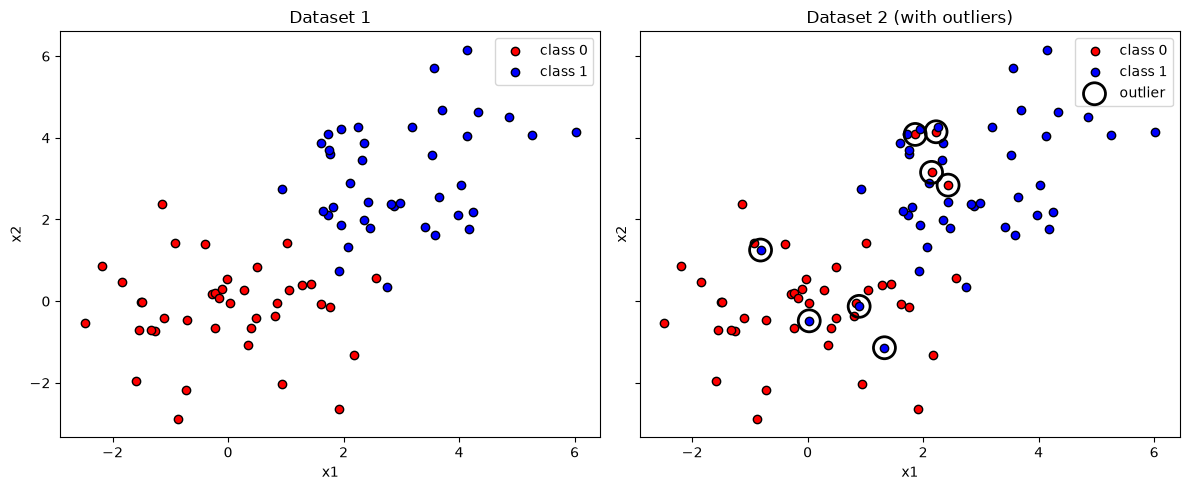

Outliers added to Dataset 1:


,x1,x2,class,outlier
80,2.432,2.841,0,True
81,2.224,4.148,0,True
82,1.862,4.083,0,True
83,2.146,3.155,0,True
84,0.892,-0.127,1,True
85,1.330,-1.141,1,True
86,-0.815,1.252,1,True
87,0.028,-0.482,1,True


In [4]:
rng = np.random.default_rng(RANDOM_STATE)
N_OUT = 4

out0 = centers[1] + rng.uniform(-1.5, 1.5, size=(N_OUT, 2))
out1 = centers[0] + rng.uniform(-1.5, 1.5, size=(N_OUT, 2))
X_out = np.vstack([out0, out1])
y_out = np.array([0] * N_OUT + [1] * N_OUT)

X2 = np.vstack([X1, X_out])
y2 = np.concatenate([y1, y_out])
is_outlier2 = np.r_[np.zeros(len(X1), dtype=bool), np.ones(len(X_out), dtype=bool)]

df2 = pd.DataFrame(X2, columns=["x1", "x2"])
df2["class"] = y2
df2["outlier"] = is_outlier2

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
for ax, (X, y, title) in zip(axes, [(X1, y1, "Dataset 1"), (X2, y2, "Dataset 2 (with outliers)")]):
    for c in (0, 1):
        ax.scatter(X[y == c, 0], X[y == c, 1], c=CLASS_COLORS[c], edgecolors="k", label=f"class {c}")
    ax.set_title(title)
    ax.set_xlabel("x1")
    ax.set_ylabel("x2")
axes[1].scatter(X_out[:, 0], X_out[:, 1], s=250, facecolors="none", edgecolors="k",
                linewidths=2, label="outlier")
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.show()

print("Outliers added to Dataset 1:")
df2[df2["outlier"]].round(3)

## B.I.3 Train / test split

In [5]:
TEST_SIZE = 0.25

X1_train, X1_test, y1_train, y1_test = train_test_split(
    X1, y1, test_size=TEST_SIZE, stratify=y1, random_state=RANDOM_STATE)
X2_train, X2_test, y2_train, y2_test, out2_train, out2_test = train_test_split(
    X2, y2, is_outlier2, test_size=TEST_SIZE, stratify=y2, random_state=RANDOM_STATE)

datasets = {
    "Dataset 1": (X1_train, X1_test, y1_train, y1_test),
    "Dataset 2": (X2_train, X2_test, y2_train, y2_test),
}

for name, (X_train, X_test, y_train, y_test) in datasets.items():
    print(f"{name}: train = {len(y_train)} points {np.bincount(y_train)}, test = {len(y_test)} points {np.bincount(y_test)}")
print(f"Dataset 2 outliers: {out2_train.sum()} in train, {out2_test.sum()} in test")


def split_table(X_train, y_train, X_test, y_test):
    tr = pd.DataFrame(X_train, columns=["x1", "x2"]).assign(**{"class": y_train, "set": "train"})
    te = pd.DataFrame(X_test, columns=["x1", "x2"]).assign(**{"class": y_test, "set": "test"})
    return pd.concat([tr, te], ignore_index=True).round(3)


split1 = split_table(X1_train, y1_train, X1_test, y1_test)
split2 = split_table(X2_train, y2_train, X2_test, y2_test)
split2["outlier"] = np.r_[out2_train, out2_test]
#display(split1)
#display(split2)

Dataset 1: train = 60 points [30 30], test = 20 points [10 10]
Dataset 2: train = 66 points [33 33], test = 22 points [11 11]
Dataset 2 outliers: 4 in train, 4 in test


## B.I.4 k-NN, Naive Bayes and SVM

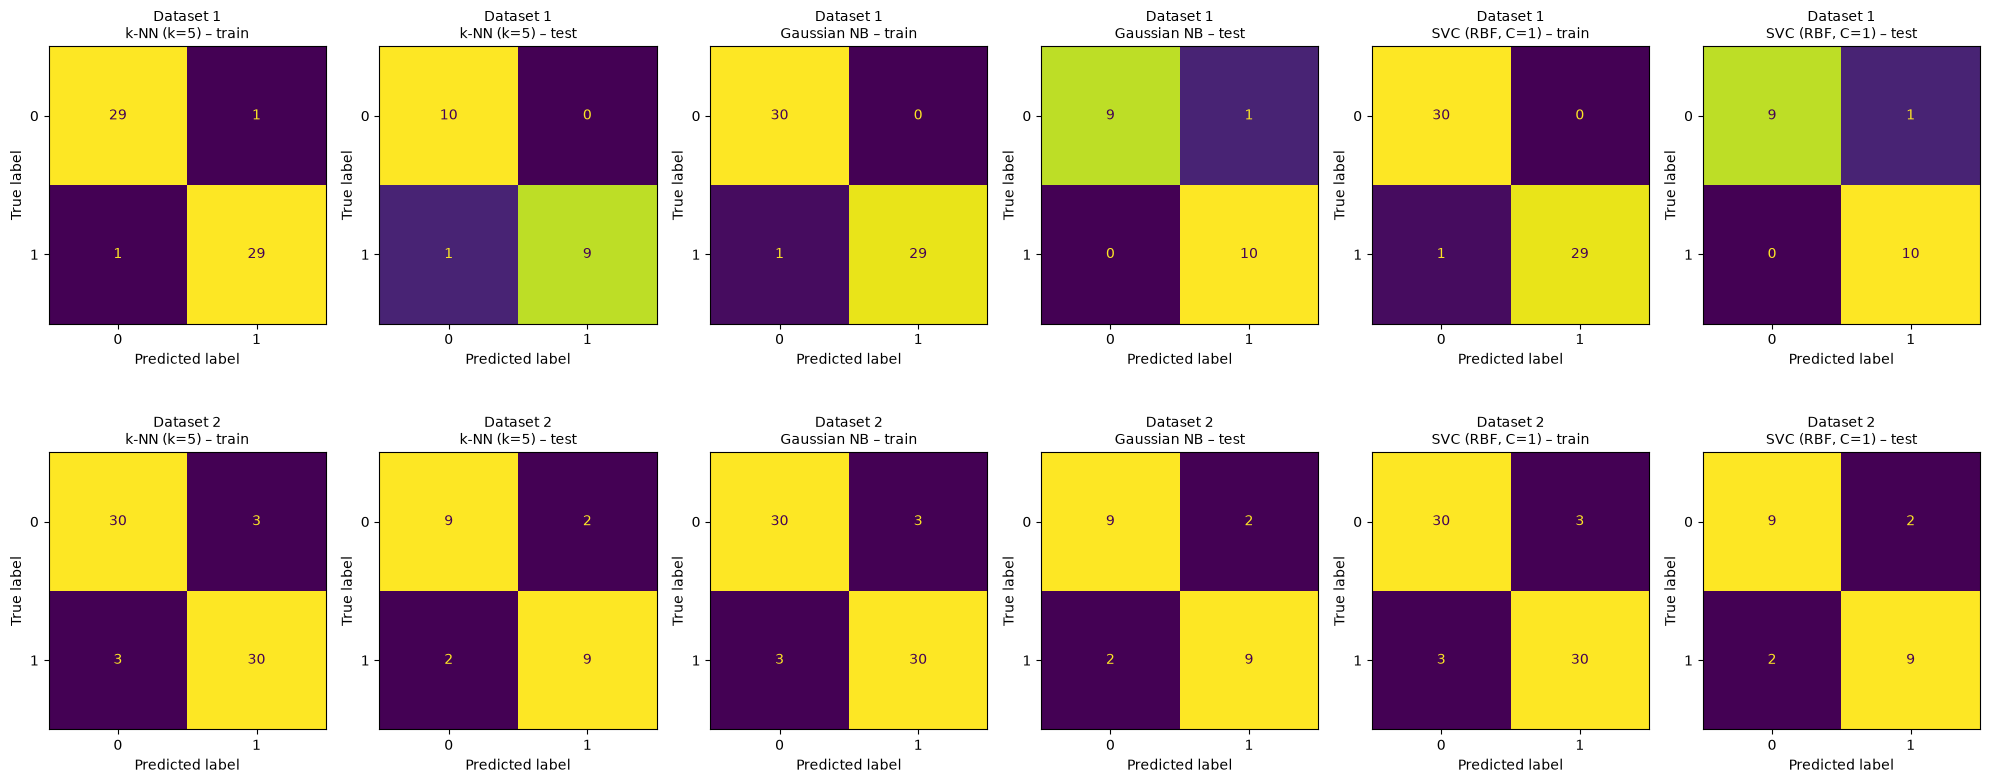

train accuracy           test accuracy          
dataset             Dataset 1 Dataset 2     Dataset 1 Dataset 2
model                                                          
Gaussian NB             0.983     0.909          0.95     0.818
SVC (RBF, C=1)          0.983     0.909          0.95     0.818
k-NN (k=5)              0.967     0.909          0.95     0.818

In [6]:
base_models = {
    "k-NN (k=5)": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
    "Gaussian NB": GaussianNB(),
    "SVC (RBF, C=1)": make_pipeline(StandardScaler(), SVC(kernel="rbf", C=1.0)),
}

results = []
fig, axes = plt.subplots(len(datasets), 2 * len(base_models), figsize=(20, 8))
for i, (dataset_name, (X_train, X_test, y_train, y_test)) in enumerate(datasets.items()):
    for j, (m_name, model) in enumerate(base_models.items()):
        model = clone(model).fit(X_train, y_train)
        pred_train, pred_test = model.predict(X_train), model.predict(X_test)
        results.append({
            "dataset": dataset_name,
            "model": m_name,
            "train accuracy": accuracy_score(y_train, pred_train),
            "test accuracy": accuracy_score(y_test, pred_test),
        })
        for k, (split, y_true, y_pred) in enumerate([("train", y_train, pred_train), ("test", y_test, pred_test)]):
            ax = axes[i, 2 * j + k]
            ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred)).plot(ax=ax, colorbar=False)
            ax.set_title(f"{dataset_name}\n{m_name} – {split}", fontsize=10)
plt.tight_layout(h_pad=3)
plt.show()

results_df = pd.DataFrame(results)
results_df.pivot(index="model", columns="dataset", values=["train accuracy", "test accuracy"]).round(3)

- the models perform nearly the same on dataset 1 and exactly the same on dataset 2.

#### Dataset 1 (without outliers)
- gaussian nb and svc (rbf) have 59/60 correct on the training set (98.3%) and 19/20 on the test set (95%).
- k-nn has 58/60 correct on the training set (96.7%) and 19/20 on the test set (95%).
- all errors are in the region where the two classes overlap.
- train and test accuracy are close to each other (96.7-98.3% and 95%), so no model overfits.

#### Dataset 2 (with outliers)
- all models have 60/66 correct on the training set (90.9%), with 3 false positives and 3 false negatives.
- all models have 18/22 correct on the test set (81.8%), with 2 false positives and 2 false negatives.
- the 6 training errors are the 4 training outliers and the 2 overlap points from dataset 1. the models don't fit the outliers but treat them as noise, so they don't overfit.
- the 4 test errors are exactly the 4 test outliers, and every other test point is classified correctly. so the drop in test accuracy from 95% to 81.8% comes only from the outliers, whose label doesn't match their location.
- all three models misclassify exactly the same points, even though they work very differently. with k = 5 and c = 1 the boundaries are smooth enough that the outliers don't pull them away from the diagonal.
- the outliers lower both the training and test accuracy.

## B.I.5 SVC: regularization parameter C and kernels

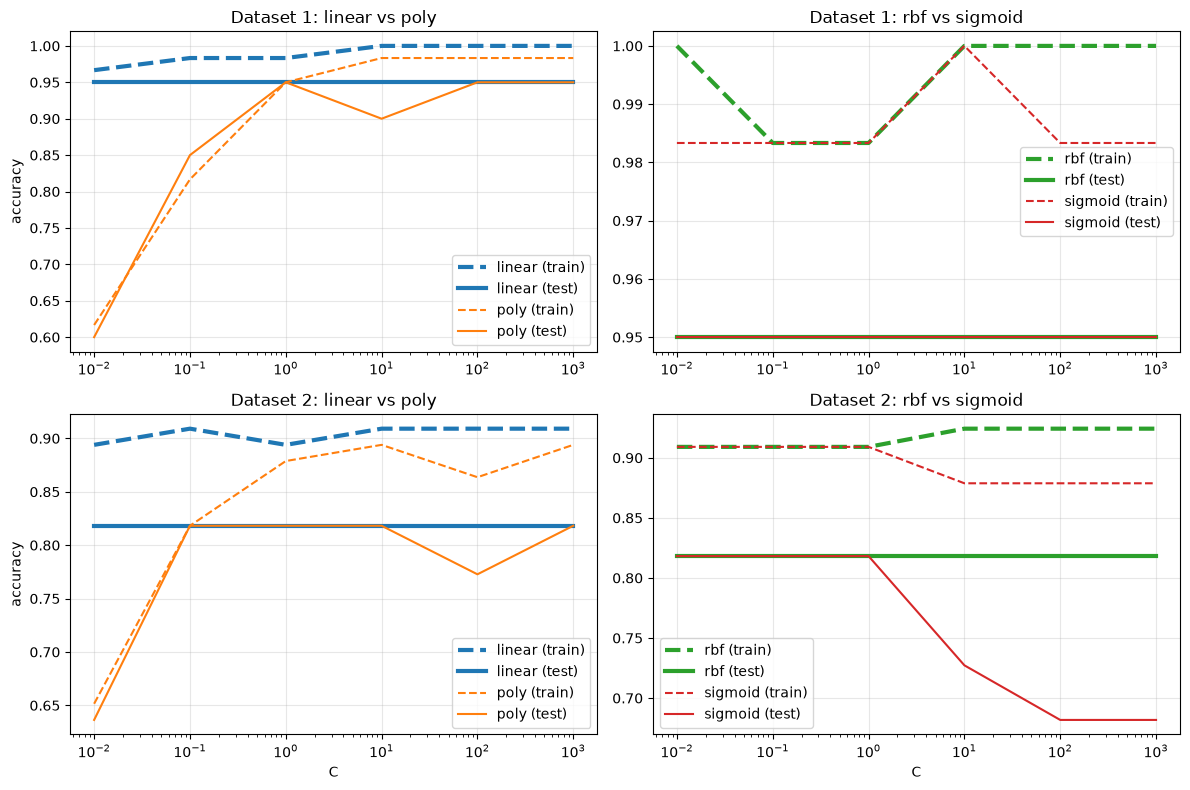

train accuracy


C                  0.01     0.10     1.00     10.00    100.00   1000.00
dataset   kernel                                                       
Dataset 1 linear     0.967    0.983    0.983    1.000    1.000    1.000
          poly       0.617    0.817    0.950    0.983    0.983    0.983
          rbf        1.000    0.983    0.983    1.000    1.000    1.000
          sigmoid    0.983    0.983    0.983    1.000    0.983    0.983
Dataset 2 linear     0.894    0.909    0.894    0.909    0.909    0.909
          poly       0.652    0.818    0.879    0.894    0.864    0.894
          rbf        0.909    0.909    0.909    0.924    0.924    0.924
          sigmoid    0.909    0.909    0.909    0.879    0.879    0.879

test accuracy


C                  0.01     0.10     1.00     10.00    100.00   1000.00
dataset   kernel                                                       
Dataset 1 linear     0.950    0.950    0.950    0.950    0.950    0.950
          poly       0.600    0.850    0.950    0.900    0.950    0.950
          rbf        0.950    0.950    0.950    0.950    0.950    0.950
          sigmoid    0.950    0.950    0.950    0.950    0.950    0.950
Dataset 2 linear     0.818    0.818    0.818    0.818    0.818    0.818
          poly       0.636    0.818    0.818    0.818    0.773    0.818
          rbf        0.818    0.818    0.818    0.818    0.818    0.818
          sigmoid    0.818    0.818    0.818    0.727    0.682    0.682

In [7]:
Cs = [0.01, 0.1, 1, 10, 100, 1000]
kernels = ["linear", "poly", "rbf", "sigmoid"]

rows = []
for dataset_name, (X_train, X_test, y_train, y_test) in datasets.items():
    for kernel in kernels:
        for C in Cs:
            model = make_pipeline(StandardScaler(), SVC(kernel=kernel, C=C)).fit(X_train, y_train)
            rows.append({
                "dataset": dataset_name,
                "kernel": kernel,
                "C": C,
                "train accuracy": model.score(X_train, y_train),
                "test accuracy": model.score(X_test, y_test),
            })
svc_results = pd.DataFrame(rows)

kernel_pairs = [("linear", "poly"), ("rbf", "sigmoid")]
kernel_colors = {"linear": "C0", "poly": "C1", "rbf": "C2", "sigmoid": "C3"}

fig, axes = plt.subplots(len(datasets), len(kernel_pairs), figsize=(12, 8))
for i, dataset_name in enumerate(datasets):
    sub = svc_results[svc_results["dataset"] == dataset_name]
    for j, pair in enumerate(kernel_pairs):
        ax = axes[i, j]
        for n, kernel in enumerate(pair):
            k = sub[sub["kernel"] == kernel]
            lw = 3 if n == 0 else 1.5
            ax.plot(k["C"], k["train accuracy"], "--", color=kernel_colors[kernel], lw=lw, label=f"{kernel} (train)")
            ax.plot(k["C"], k["test accuracy"], "-", color=kernel_colors[kernel], lw=lw, label=f"{kernel} (test)")
        ax.set_xscale("log")
        ax.set_title(f"{dataset_name}: {pair[0]} vs {pair[1]}")
        ax.grid(alpha=0.3)
        ax.legend(loc="best")
        if i == len(datasets) - 1:
            ax.set_xlabel("C")
        if j == 0:
            ax.set_ylabel("accuracy")
plt.tight_layout()
plt.show()

for metric in ["train accuracy", "test accuracy"]:
    print(metric)
    display(svc_results.pivot_table(index=["dataset", "kernel"], columns="C", values=metric).round(3))


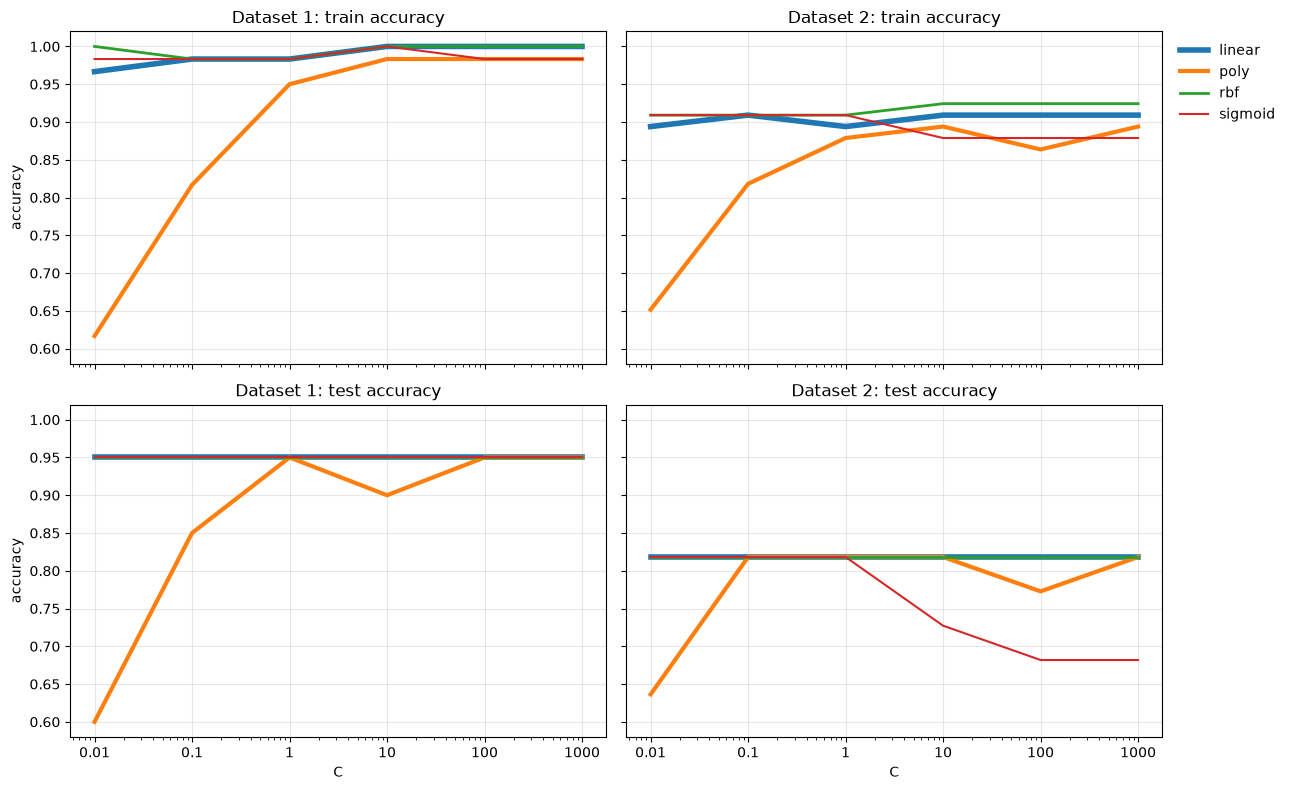

In [12]:
kernel_colors = {"linear": "C0", "poly": "C1", "rbf": "C2", "sigmoid": "C3"}
kernel_widths = {"linear": 4, "poly": 3, "rbf": 2, "sigmoid": 1.5}
metrics = ["train accuracy", "test accuracy"]

fig, axes = plt.subplots(len(metrics), len(datasets), figsize=(13, 8), sharex=True, sharey=True)
for i, metric in enumerate(metrics):
    for j, dataset_name in enumerate(datasets):
        ax = axes[i, j]
        sub = svc_results[svc_results["dataset"] == dataset_name]
        for kernel in kernels:
            k = sub[sub["kernel"] == kernel]
            ax.plot(k["C"], k[metric], color=kernel_colors[kernel], lw=kernel_widths[kernel], label=kernel)
        ax.set_xscale("log")
        ax.set_xticks(Cs)
        ax.set_xticklabels(Cs)
        ax.set_title(f"{dataset_name}: {metric}")
        ax.grid(alpha=0.3)
        if i == len(metrics) - 1:
            ax.set_xlabel("C")
        if j == 0:
            ax.set_ylabel("accuracy")
axes[0, -1].legend(loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False)
plt.tight_layout()
plt.show()

- both c and kernel can affect the accuracy.
- the best choice would be linear or RBF kernel with a c value between 0.1-1.
- linear and rbf have the same test accuracy for every c (95% on dataset 1, 81.8% on dataset 2), since the data is almost linearly separable and the remaining errors are the overlap point and the outliers.
- the training accuracy goes up slightly with a larger c, as we can see on linear and rbf, but the test accuracy doesn't, so this means that there is overfitting.
- poly with a small c underfits: at c = 0.01 it only reaches about 60-65% and predicts class 0 for almost every point. from c = 0.1-1 it gets close to the other kernels.
- on dataset 1 the rbf and sigmoid test accuracies are the same for every c (95%), so their lines overlap in the plot.

## B.I.6 Decision boundaries

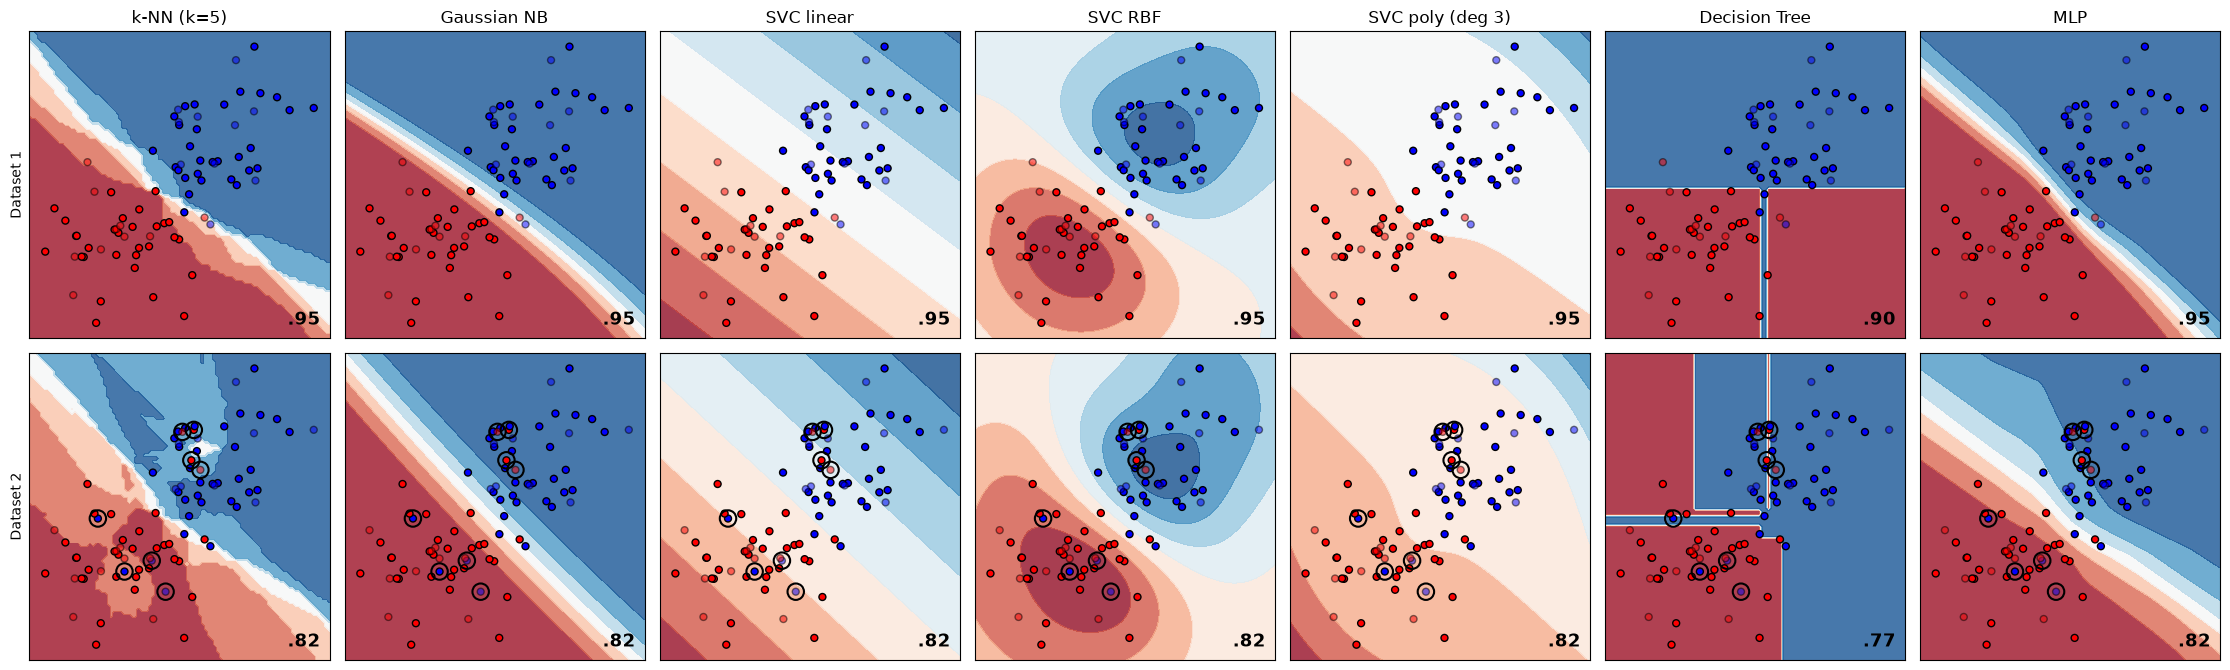

In [9]:
classifiers = {
    "k-NN (k=5)": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
    "Gaussian NB": GaussianNB(),
    "SVC linear": make_pipeline(StandardScaler(), SVC(kernel="linear", C=1.0)),
    "SVC RBF": make_pipeline(StandardScaler(), SVC(kernel="rbf", C=1.0)),
    "SVC poly (deg 3)": make_pipeline(StandardScaler(), SVC(kernel="poly", degree=3, C=1.0)),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, random_state=RANDOM_STATE),
    "MLP": make_pipeline(StandardScaler(), MLPClassifier(hidden_layer_sizes=(16, 16), max_iter=2000,
                                                         random_state=RANDOM_STATE)),
}

cm = plt.cm.RdBu
cm_bright = ListedColormap(CLASS_COLORS)

fig, axes = plt.subplots(len(datasets), len(classifiers), figsize=(3.2 * len(classifiers), 6.8))
for i, (dataset_name, (X_train, X_test, y_train, y_test)) in enumerate(datasets.items()):
    X_all = np.vstack([X_train, X_test])
    for j, (clf_name, clf) in enumerate(classifiers.items()):
        ax = axes[i, j]
        clf = clone(clf).fit(X_train, y_train)
        score = clf.score(X_test, y_test)
        DecisionBoundaryDisplay.from_estimator(clf, X_all, cmap=cm, alpha=0.8, ax=ax, eps=0.5)
        ax.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap=cm_bright, edgecolors="k", s=25)
        ax.scatter(X_test[:, 0], X_test[:, 1], c=y_test, cmap=cm_bright, edgecolors="k", alpha=0.5, s=25)
        if dataset_name == "Dataset 2":
            ax.scatter(X_out[:, 0], X_out[:, 1], s=140, facecolors="none", edgecolors="k", linewidths=1.5)
        ax.text(0.97, 0.03, f"{score:.2f}".lstrip("0"), transform=ax.transAxes,
                ha="right", va="bottom", fontsize=13, weight="bold")
        ax.set_xticks(())
        ax.set_yticks(())
        ax.set_xlabel("")
        ax.set_ylabel(dataset_name if j == 0 else "")
        if i == 0:
            ax.set_title(clf_name)
plt.tight_layout()
plt.show()

- the background shows how confident each model is: red = class 0, blue = class 1, pale/white = uncertain (close to the boundary). training points have a black edge, test points are faded, the outliers are circled, and the number in the corner is the test accuracy.

#### Dataset 1 (without outliers)
- every model puts the boundary along the diagonal between the two clusters, and all reach 95% test accuracy except the decision tree (90%).
- k-nn has a jagged, irregular boundary that follows the training points around it.
- gaussian nb has a smooth, slightly curved boundary. it is quadratic because each class has its own variance, but since both clusters have the same spread it is almost straight.
- svc linear has a straight boundary, and the confidence grows steadily with the distance from it.
- svc rbf has a smooth curved boundary, and the confidence forms rings around each cluster.
- svc poly has a curved boundary with a wide pale (uncertain) area away from the data.
- the decision tree can only make axis-aligned rectangles. it cuts out a thin vertical strip to fit a single overlap point, so it reaches 100% on train but only 90% on test, which is overfitting.
- the mlp has a smooth, almost straight boundary, similar to the linear svc (100% train, 95% test).

#### Dataset 2 (with outliers)
- all models except the decision tree ignore the outliers: none of the 4 training outliers is fitted, and the boundary stays close to the one on dataset 1. they all reach 81.8% test accuracy, and their only test errors are the 4 test outliers.
- k-nn reacts the most: its boundary becomes more irregular around the outliers, with paler regions and small bulges, but with k = 5 the outliers are still outvoted by their neighbours.
- nb, the svcs and the mlp only shift slightly; the outliers mostly make the colours paler (less confident) around them.
- the decision tree fits all 4 training outliers with thin rectangular strips (100% train). one normal test point falls into one of these strips, so it has the lowest test accuracy (77.3%). this is the clearest case of overfitting.

## B.I.7 Similarities and differences between the models

#### Similarities
- all models are supervised and learn from the same labelled data.
- on dataset 1 they all find almost the same diagonal boundary and reach 95% test accuracy (decision tree 90%), because the problem is easy and close to linear.
- on dataset 2 all models except the decision tree treat the outliers as noise and make exactly the same test errors.

#### Differences
- k-nn votes among the nearest training points, so its boundary is jagged and follows the local data. the outliers make it more irregular, but with k = 5 they are outvoted.
- gaussian nb fits one gaussian per class and uses bayes' rule. its boundary is smooth and it is very robust, because 4 outliers barely change the means and variances.
- svc finds the boundary with the widest margin: a straight line for the linear kernel, a smooth curve for rbf and poly. with c = 1 it ignores the outliers, but with a large c it bends towards them (b.i.5).
- the decision tree splits on one feature at a time, so its boundary is made of rectangles. it fits every training outlier with thin strips and has the lowest test accuracy (77.3%), so it overfits the most.
- the mlp gives a smooth, almost straight boundary and is robust here, but a bigger network could overfit.
- k-nn and decision tree are sensitive to single points, while nb and linear svc use all the data and are more robust to outliers.

# B.II Bias-Variance tradeoff

## B.II.1 k-NN with different k

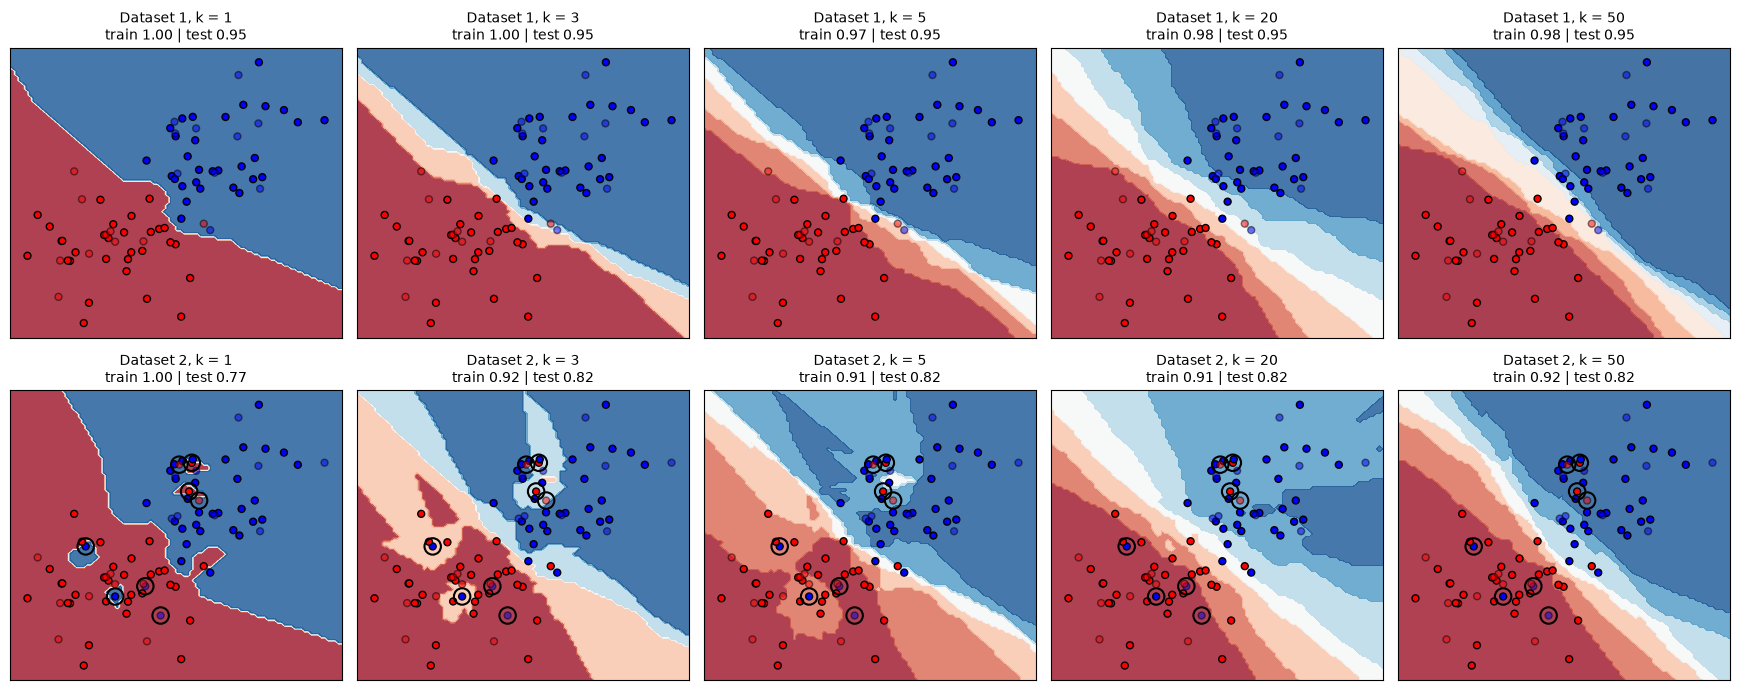

train accuracy           test accuracy          
dataset      Dataset 1 Dataset 2     Dataset 1 Dataset 2
k                                                       
1                1.000     1.000          0.95     0.773
3                1.000     0.924          0.95     0.818
5                0.967     0.909          0.95     0.818
20               0.983     0.909          0.95     0.818
50               0.983     0.924          0.95     0.818

In [10]:
ks = [1, 3, 5, 20, 50]

knn_rows = []
fig, axes = plt.subplots(len(datasets), len(ks), figsize=(3.5 * len(ks), 7))
for i, (dataset_name, (X_train, X_test, y_train, y_test)) in enumerate(datasets.items()):
    X_all = np.vstack([X_train, X_test])
    for j, k in enumerate(ks):
        ax = axes[i, j]
        knn = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k)).fit(X_train, y_train)
        train_acc, test_acc = knn.score(X_train, y_train), knn.score(X_test, y_test)
        knn_rows.append({"dataset": dataset_name, "k": k, "train accuracy": train_acc, "test accuracy": test_acc})

        DecisionBoundaryDisplay.from_estimator(knn, X_all, cmap="RdBu", alpha=0.8, ax=ax, eps=0.5)
        ax.scatter(X_train[:, 0], X_train[:, 1], c=np.array(CLASS_COLORS)[y_train], edgecolors="k", s=25)
        ax.scatter(X_test[:, 0], X_test[:, 1], c=np.array(CLASS_COLORS)[y_test], edgecolors="k", alpha=0.5, s=25)
        if dataset_name == "Dataset 2":
            ax.scatter(X_out[:, 0], X_out[:, 1], s=140, facecolors="none", edgecolors="k", linewidths=1.5)
        ax.set_title(f"{dataset_name}, k = {k}\ntrain {train_acc:.2f} | test {test_acc:.2f}", fontsize=10)
        ax.set_xticks(())
        ax.set_yticks(())
        ax.set_xlabel("")
        ax.set_ylabel("")
plt.tight_layout()
plt.show()

knn_df = pd.DataFrame(knn_rows)
knn_df.pivot(index="k", columns="dataset", values=["train accuracy", "test accuracy"]).round(3)

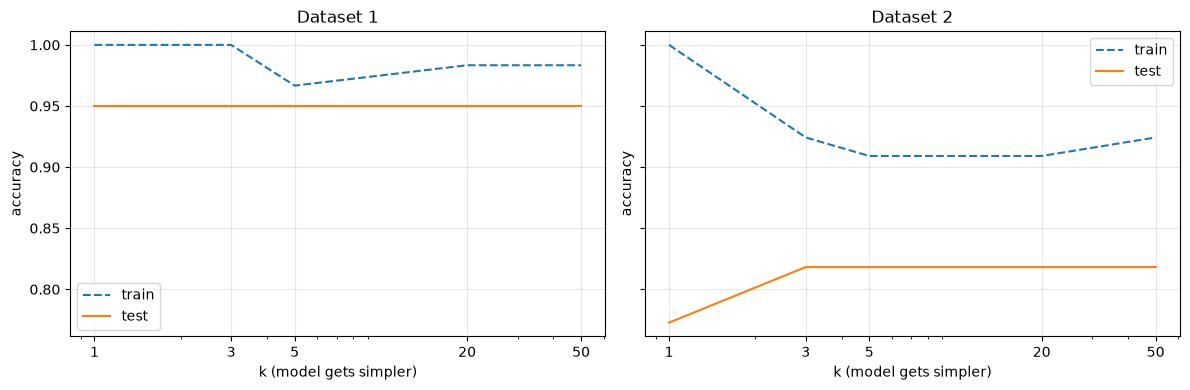

In [11]:
fig, axes = plt.subplots(1, len(datasets), figsize=(12, 4), sharey=True)
for ax, dataset_name in zip(axes, datasets):
    sub = knn_df[knn_df["dataset"] == dataset_name]
    ax.plot(sub["k"], sub["train accuracy"], "--", label="train")
    ax.plot(sub["k"], sub["test accuracy"], "-", label="test")
    ax.set_xscale("log")
    ax.set_xticks(ks)
    ax.set_xticklabels(ks)
    ax.set_xlabel("k (model gets simpler)")
    ax.set_ylabel("accuracy")
    ax.set_title(dataset_name)
    ax.grid(alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()

- increasing k makes the boundary smoother and less sensitive to individual points, which can be seen on dataset 2.
- for small k, dataset 1 and dataset 2 give very different class regions.
- for large k, the plots of the datasets look almost the same.
- with k = 50, each vote covers 50 of the 60–66 training points, so in most of the plane the vote is close to 50/50 (wide pale area).

## B.II.2 Bias-variance tradeoff

$$\mathbb{E}[\text{error}] = \text{Bias}^2 + \text{Variance} + \text{irreducible noise}$$

- bias is the error from a model that is too simple to capture the true split between classes.
- variance is the error from a model that depends too much on the exact training points, so a slightly different training set gives a very different model.
- irreducible noise can't be removed by any model, for example the overlap points and the outliers.
- lowering bias usually raises variance and the other way around, so the best k is the one that balances the two.

#### Relation to k
- small k (k = 1) means low bias and high variance: the model can take any shape and changes with every single point. on dataset 2 every training outlier gets its own island and one normal test point falls into one, so the model reaches 100% train but only 77.3% test. this is overfitting.
- large k (k = 20, 50) means high bias and low variance: the model can only draw a smooth, almost straight line, and both datasets give almost the same result, so outliers no longer matter.
- in this example, a large k doesn't lose accuracy, because the true boundary between the two clusters is straight. if the classes were separated by a curve, or with k close to the number of training points (the model would then predict the same class everywhere), it would underfit: both train and test accuracy would drop.
- k = 3-20 gives a good balance on this data: the outliers are ignored and the test accuracy is the highest (81.8% on dataset 2).
- the test sets are very small (one point ≈ 5%), so the data can't pick one exact best k. cross-validation (exercise d) would give a more reliable choice.